In [39]:
import numpy as np
import matplotlib.pyplot as plt

# **What determines whether a gene spreads or disappears?**

## Mathematical modeling and Python simulations of population genetics

### 1. Introduction

#### 1.1 The problem
The rapid advancement of technology enables us to transform real-world objects into models that can be studied in detail by modifying them and observing their behavior in an isolated environment. The most practical application of such concepts lies in the field of biology, allowing for the study of human genes through the simulation of their behavior and characteristics, testing under extreme conditions, and so on. 

It is clear that some genetic variants become more common in a population, while others become less common or disappear completely. This may seem like something predictable - e.g. if one allele has an advantage we might expect it to become more common over time. However, populations are not deterministic systems and random events can influence which alleles are passed to the next generation. 

In this project, I am investigating an interesting mathematical question:

***Can mathematics predict how an allele will spread through a population?***

My survey uses a simple mathematical model and Python simulations.

#### 1.2 Research question

The main reserach question of this project is:

***How accurately can mathematical models predict the spread or disappearance of an allele, and how do population size, genetic drift and natural selection affect this prediction?***

The main topic includes many components that have to be studied carefully, so the survey is based on several smaller questions:

>* How does population size affect genetic drift?
>* Does the initial frequency of an allele affect its chance of becoming fixed or disappearing?
>* How does natural selection affect allele frequency?
>* How different are deterministic and stochastic models?
>* Can we predict an exact evolutionary trajectory or only probabilities and statistical properties?


#### 1.3 Result predictions
1. Larger populations are expected to show smaller fluctuations in allele frequency between generations
2. An allele with higher initial frequency is expected to have bigger chance of becoming fixed
3. An allele with higher fitness is expected to have bigger chance of becoming fixed
4. In the absence of selection, an allele is expected to have a probability of fixation close to its initial frequency
5. Increasing the strength of natural selection in favor of an allele is expected to increase its probability of becoming fixed


#### 1.4 Project map
1. Introducing biological concepts of allele frequency, genetic drift and natural selection
2. Creating mathematical model 
3. Working with Deterministic model
4. Working with Stochastic model
5. Performing experiments by changing model's parameters
6. Analyzing results

### 2. Biological background

#### 2.1 Allele

An allele is one version of a gene. For example, the color of person's eyes is a gene, while black, brawn, blue are the alleles for this specific gene. For the purposes of this project, I will use two abstract alleles:
***A*** and ***a***. 

#### 2.2 Allele frequency

Allele frequency describes how common an allele is in a population. If there are 100 copies of an allele (that means that our population consist of 100 individuals) and 30 of them are ***A***, then $$p_\text{A} = \frac{30}{100} = 0.30$$
Therefore, the allele frequency of allele A is 30%. The frequency of the other allele (***a***) is then $$p_\text{a} = 1-p_\text{A}$$ In our example that means 0.70 or 70%. One of the main variables being tracked by my project will be namely allele frequency.






In [40]:
#Allele frequencies at starting generation
p_0 = 0.5
q_0 = 1- p_0
print("Initial frequency of allele A: ", p_0)
print("Initial frequency of allele a: ", q_0)

Initial frequency of allele A:  0.5
Initial frequency of allele a:  0.5


#### 2.3 Allele fitness

Allele fitness measures the reproductive success of one allele when shuffled across the various genetic backgrounds of a population. Alleles with higher biological fitness leave more copies in the next generation, while low-fitness alleles are gradually eliminated.

#### 2.4 Genetic drift

Genetic drift means a random change in allele frequency. Even if two alleles have the same biological fitness, their frequences may change because of random sampling. For example, if the initial frequency of ***A*** is as follows: $$p_\text{A} = 0.5$$ after one generation, random sampling could give the result $$p_\text{A} = 0.56$$ <br> After many generations, the frequency could eventually reach 1, which means that ***A*** has become fixed. Alternatively, it could reach 0, which means that ***A*** has completely disappeared. <br> Important feature of genetic drift is that it is stronger in smaller populations, as we can observe: If one individual in a population of 10 individuals dies before it leaves any genetics to the next generation, 10% of this population's gene pool is irreversaly lost[[1]](#ref1). In a generation of 100 individuals, one individual's death means losing 1% genetical information and so on. 

#### 2.5 Natural selection

Natural selection may also result in changes in allele frequency along with genetic drift. The environment determines whether an allele increases or decreases in a population over time, depending on the phenotype it expresses[[1]](#ref1). This can be represented using a selection coefficient $s$ and define the fitness of allele ***A*** as $$w_\text{A} = 1+s$$ while allele ***a*** has fitness 1. This means that ***A*** has a small advantage over ***a***. The larger the value of ***s*** is, the stronger the effect of selection is.

In [41]:
selection_strength = 0.05
fitness_A = 1 + selection_strength
fitness_a = 1
print(f"Allele A has {fitness_A-fitness_a} higher fitness than allele a with selection strength {selection_strength}")


Allele A has 0.050000000000000044 higher fitness than allele a with selection strength 0.05


### 3. Mathematical model

#### 3.1 Population parameters

Assuming that a population contains of $N$ diploid individuals (meaning that each individual has two copies of the gene) the total number of allele copies is $2N$. 



In [42]:
population_size = 100
allele_copies = 2*population_size
initial_generation = 0
number_of_generations = 500
print(f"Population of {population_size} diploid individuals has {allele_copies} copies of allele A")

Population of 100 diploid individuals has 200 copies of allele A


If $t$ represents the generation number, then $X_t$ will be the number of copies of allele ***A*** in generation $t$. The relationship between allele frequency and the number of ***A*** copies is as follows [[2]](#ref2): $$p_t = \frac{X_t}{2N}$$ Therefore $$X_t = 2*N*p_t$$ For example if $N$ is 100 and $p_0 = 0.5$ then the expected number of ***A*** copies is $$X_0 = 2*100*0.5 = 100$$

In [43]:
initial_frequency = 0.5
A_copies = initial_frequency * allele_copies
print(f"Initial allele frequency of {initial_frequency} gives us {A_copies} expected copies of allele A")

Initial allele frequency of 0.5 gives us 100.0 expected copies of allele A


### 4. Probability and Binomial distribution

#### 4.1 Binomial distribution 

This is the key mathematical idea that lies behind the used stochastic model. It summarizes the likehood that a value will take one of two independent values under a given number of parameters.

#### 4.2 Stochastic model 

A stochastic model is used to estimate the probability of various outcomes when random variables are present, incorporating randomness and uncertainty. This means running the same model multiple times will yield different results, which represents real-world unpredictability. 

As I mentioned in the previous chapter, the frequency of allele ***A*** in generation $t$ is labeled as $p_t$. Therefore, the number of ***A*** copies in next generation is modeled as follows: $$X_{t+1}\sim Binomial(2N, p_t)$$  This means that $X_{t+1}$ is a random variable. $2N$ and $p_t$ are important parameters for Binomial distribution, as $2N$ represents the total number of genes being examined and $p_t%$ represents the probability of allele ***A*** succeeding in each trial. The probability of obtaining $k$ copies of ***A*** is[[3]](#ref3): $$P(X=k)=\binom{2N}{k} p^k(1-p)^{2N-k}$$

In [44]:
number_of_A = np.random.binomial(allele_copies,initial_frequency)
print("Random number of A copies: ", number_of_A)
new_frequency = number_of_A/allele_copies
print("New frequency of A: ", new_frequency)

Random number of A copies:  102
New frequency of A:  0.51


*Note that the number of A copies changes each time the cell is executed. Respectively, the frequency also changes.*

### 5. Expected value and variance

The most likely outcome the used stochastic model would give us if the process is repeated many times is in general represented as follows[[3]](#ref3): $$E[X] = np$$ In my model $n$ is actually $2N$ as it represents the total number of gene copies and $p$ is the current frequency of allele - $p_t$. 
Because a stochastic model is used, the actual number of gene copies in the next generation won't always equal the expected value due to random chance. The variance is in general calculated with the following formula: $$Var(X) = n*p*(1-p)$$ and in my specific model it transforms as follows: $$Var(X) = 2N * p_t * (1-p_t)$$

In [45]:
expected_value = allele_copies*initial_frequency
variance = (allele_copies*initial_frequency*(1-initial_frequency))
print("Expected number of A copies: ", expected_value)
print("Theoretical variance: ", variance)

Expected number of A copies:  100.0
Theoretical variance:  50.0


### 6. Deterministic model

The simpliest possible model is the deterministic one. The difference between deterministic and stochastic model is that deterministic models rely on fixed rules and initial conditions, while stochastic models include randomness. Therefore, creating my deterministic model includes no selection, no mutation, no migration and no genetic drift. <br> Allele frequency also remains the same. Therefore $p_{t+1} = p_t$. If $p_0 = 0.5$ then $p_1=p_2=p_3=\dots=0.5$

TypeError: 'str' object is not callable

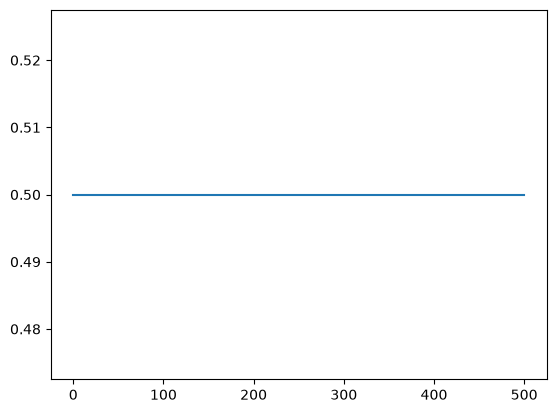

In [46]:
deterministic_frequency = initial_frequency
deterministic_frequencies = []
for generation in range(number_of_generations+1):
    deterministic_frequencies.append(deterministic_frequency)

plt.plot(deterministic_frequencies, label="Deterministic model")
plt.xlabel("Generation")
plt.ylabel("Frequency of allele A")
plt.show()


### 7. Stochastic model
As I mentioned previously stochastic model incorporates probability distributions into the process. Including genetic drift the mathematical model becomes $X_{t+1}\sim Binominal(2N,p_t)$ and $p_{t+1}= \frac{X_{t+1}}{2N}$. <br>This makes the difference between the deterministic and the stochastic model obvious: in the deterministic one $p_{t+1}=p_t$. In the stochastic one $p_{t+1}$ is generated randomly. The main function (it is introduced in the next part - `simulate_population()` uses stochastic model in order to introudce the natural effect of "random" iheritance of genes in the nature. It is influenced by many factors, such as parameters I mentioned (genetic drift, natural selection), but also mutation, migration and so on. The binomial distribution does not directly determine allele frequencies, but simulates the random allele transmition between generations. This model structure allows to study how allele frequencies may change over time. 

### 8. Main implementation

In this chapter the mathematical variables are combined into one function in order to plot the dependence between allele frequency and other parameters in the following experiments with data such as population size, initial frequency and selection strength. 


In [47]:
def simulate_population(population_size, initial_frequency, generations = number_of_generations, selection = 0):
    allele_copies = 2*population_size
    frequency = initial_frequency
    population_frequencies = []

    for generation in range(generations):
        if selection != 0:
            frequency = (frequency*(1+selection))/(frequency*(1+selection)+(1-frequency))
        A_copies = np.random.binomial(allele_copies,frequency)
        current_frequency = A_copies/allele_copies
        population_frequencies.append(current_frequency)
        frequency = current_frequency

    return population_frequencies


### 9. Experiment 1 - Population size
The first research question I am investigating is how does population size affect allele frequencies? My basic assumption is that in smaller generations there are stronger fluctations because one of the parameters that the stochastic process depends on is $2N$ (namely, the total number of allele copies, which are determined by the number of individuals). Also, in smaller generations the difference between allele frequencies should be more visible since the experiments are performed on a smaller set of objects, while in big populations the difference between allele frequencies shouldn't be so obvious. 


TypeError: 'str' object is not callable

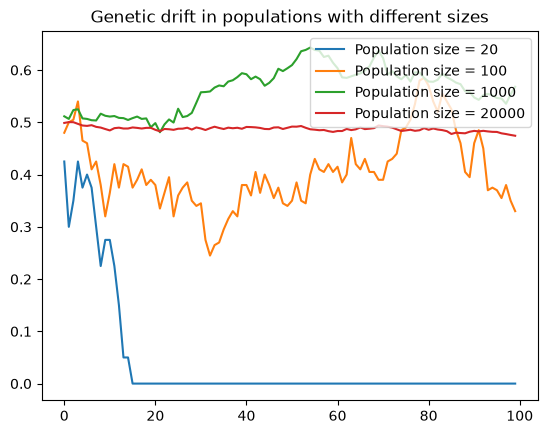

In [48]:
population_sizes = [20,100,1000,20000]
for size in population_sizes:
    current_population = simulate_population(size,initial_frequency,100)
    plt.plot(current_population, label = f"Population size = {size}")
plt.title("Genetic drift in populations with different sizes")
plt.legend(loc="upper right")
plt.xlabel("Number of generation")
plt.ylabel("Allele frequency")
plt.show()


The experiment proves my thesis that in smaller populations the "noise" (or the difference in allele frequency between generations) is more visible, while in bigger populations the function, presenting the dependence allele frequency-population size, leans to a straight line. What looks interesting is that this line tends to be close to the value of our initial frequency ($p_0=0.5$ in this case).

### 10. Experiment 2 - Initial frequency
This experiment requires to keep the population size constant. The parameter that gets changed is the initial frequency (the number of ***A*** allele copies in the first generation). The single simulation wouldn't be able to tell what is the probability of fixation(that's why repeated simulations are made as a part of the next experiments). But observing the function that was plotted in the experiment with different population sizes showed that allele frequency in bigger generations tends to be close to the initial value.

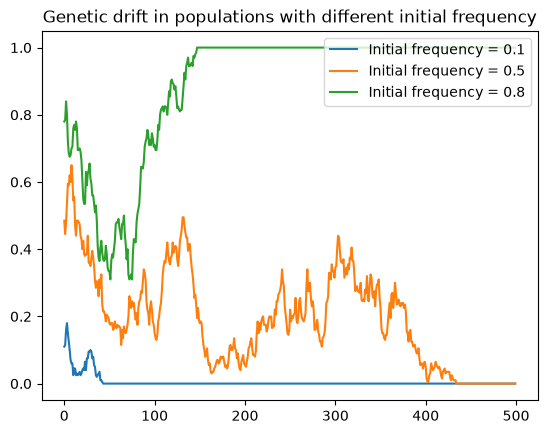

In [49]:
allele_frequencies = [0.1, 0.5, 0.8]
for frequency in allele_frequencies:
    current_population = simulate_population(population_size, frequency)
    plt.plot(current_population, label = f"Initial frequency = {frequency}")
plt.title("Genetic drift in populations with different initial frequency")
plt.legend(loc = "upper right")
plt.xlabel = "Number of generation"
plt.ylabel = "Allele frequency"
plt.show()

This experiment asserts what was already showed in the previous plot - initial allele frequency is the value, which can determine aproximately what is the frequency of this allele in the next generations. <br> What looks interesting is that the graph, representing $p_0$ = 0.1 often reaches zero, which means that allele ***A*** got extinct and its frequency remanied the same in the next generations. If no individual has allele ***A*** in its genes, then there is no way for ***A*** to be spread in the future, which is expected. Also, if every single individual in one population has the allele, then there is no other variance of the gene, represented by ***A***, that can be inherited. <br>This raises some interesting questions: Is it possible for a gene to completely lose one of its variances (which means an extinction of one allele and fixation of the other one)? What does this event depend on? 

#### 10.1 Allele fixation and extinction depending on allele frequency
In a closed population without new mutations fluctuation will not continue indefinitely and an allelle will eventualy reach one of two abssorbing boundaries: complete extinction or complete fixation. This depends fundamentally on it initial allele frequency[[5]](#ref5).<br>
In a model with no selective advantage the probability of allele reaching fixation is equal to its initial frequency. Random sampling process causes frequencies to bounce up and down unpredictably, but alleles starting near the lower boundary are far more likely to disappear from the gene pool. The most basic explanation is that in a fair genetic lottery all alleles have an equal chance of survivng and only one gene copy from the initial population will "win" and reach fixation. For example 10% initial frequency means owning 10% of the "lottery tickets". Therefore, if a specific allele holds some part of the gene pool at the start, its probability of fixation is exactly equal to that initial share. That's why allele fixation and extinction depend on the initial allele frequency.

### 11. Experiment 3 - Selection strength
As i explained selection strength means an allele having adavntage or disadvantage(determined by the environment), which determines its representation in the next generation. An important fact is that an individual wearing the allele with advantage is expected to be more reproductive. That leads to my main suggestion: allele with higher fitness is expected to have higher frequency in the next generations.

TypeError: 'str' object is not callable

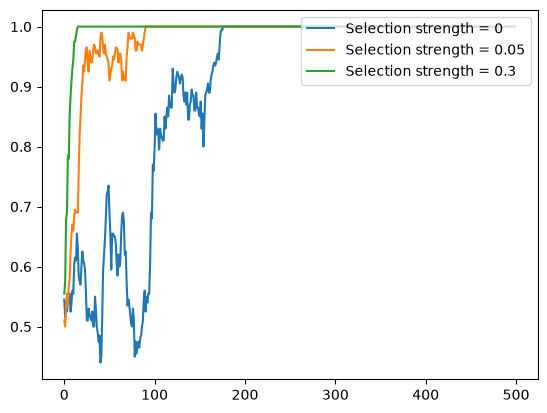

In [56]:
selection_strengths = [0, 0.05, 0.3]
for selection in selection_strengths:
    current_population = simulate_population(population_size, initial_frequency,number_of_generations,selection)
    plt.plot(current_population,label = f"Selection strength = {selection}")
plt.legend(loc="upper right")
plt.xlabel("Number of generation")
plt.ylabel("Allele frequency")
plt.show()

As expected, alleles with higher selection strength have also higher chance of becoming fixed. What is also visible from the plot is that they become fixed earlier that those with lower seelction strength.

### Resources
<a id="ref1"></a>1. Fowler, Samantha, et al. "11.2 Mechanisms of Evolution." Concepts of Biology, OpenStax, 25 Apr. 2013, https://openstax.org/books/concepts-biology/pages/11-2-mechanisms-of-evolution. Accessed [09 Oct. 2026]. <br>
<a id="ref2"></a>2. Khan Academy. "Allele frequency and the gene pool." Biology, Khan Academy, https://www.khanacademy.org/science/biology/her/heredity-and-genetics/a/allele-frequency-the-gene-pool. Accessed [09 Oct. 2026]. <br>
<a id="ref3"></a>3. "Binomial distribution." Wikipedia, The Free Encyclopedia, Wikimedia Foundation, [11 September 2026], https://en.wikipedia.org/wiki/Binomial_distribution. Accessed [10 October 2026]. <br>
<a id="ref4"></a>4. Khan Academy. "Genetic drift." Biology, Khan Academy, https://bg.khanacademy.org/science/ap-biology/natural-selection/population-genetics/a/genetic-drift-founder-bottleneck. Accessed [20 Oct. 2026]. <br>
<a id="ref5"></a>5. Pritchard, J. K. (2023). "Genetic drift." In "An Owner's Guide to the Human Genome" Stanford University. Accesses [20 Oct. 2026].<br>
